In [1]:
# =============================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# =============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Splitting and Cross Validation
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
    cross_val_score
)

# Machine Learning Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

# Feature Scaling
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model Evaluation
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import warnings
warnings.filterwarnings("ignore")

# Plot Settings
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["font.size"] = 11

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# =============================================
# STEP 1: DATA IMPORT AND INITIAL INSPECTION
# =============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# File location
file_path = r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE\Vehicle Class wise\Two Wheelers_165.xlsx"

# Load dataset
df = pd.read_excel(file_path)

# Display first five observations
print("FIRST FIVE OBSERVATIONS")
print("=" * 50)
display(df.head())

FIRST FIVE OBSERVATIONS


,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
0,1,56.15,1.27,inf,5.5,0.9,Gravel,0.9,Gravel,3.70
1,2,35.00,2.92,46.0,5.5,0.9,Gravel,0.9,Gravel,4.51
2,3,43.85,7.97,inf,5.5,0.9,Gravel,0.9,Gravel,4.39
3,4,45.15,2.07,inf,5.5,0.9,Gravel,0.9,Gravel,4.69
4,5,40.00,1.21,16.0,5.5,0.9,Gravel,0.9,Gravel,5.57


In [3]:
# =============================================
# DATASET STRUCTURE
# =============================================

print("DATASET INFORMATION")
print("=" * 50)

print("\nDataset Shape:", df.shape)

print("\nTotal Observations:", df.shape[0])

print("\nTotal Variables:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDetailed Dataset Information:")
df.info()

DATASET INFORMATION

Dataset Shape: (165, 10)

Total Observations: 165

Total Variables: 10

Column Names:
['SN', 'V85 Speed', 'Gradient', 'Radius of Curve', 'Carriageway Width', 'Left Shoulder Width', 'Left Shoulder Type', 'Right Shoulder Width', 'Right Shoulder Type', 'IRI']

Data Types:
SN                        int64
V85 Speed               float64
Gradient                float64
Radius of Curve         float64
Carriageway Width       float64
Left Shoulder Width     float64
Left Shoulder Type          str
Right Shoulder Width    float64
Right Shoulder Type         str
IRI                     float64
dtype: object

Detailed Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SN                    165 non-null    int64  
 1   V85 Speed             165 non-null    float64
 2   Gradient              165 non-null    flo

In [4]:
# =============================================
# DATA QUALITY CHECK
# =============================================

print("DATA QUALITY CHECK")
print("=" * 50)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate observations
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Unique observation IDs
print("\nUnique SN Values:")
print(df["SN"].nunique())

# Check radius values
print("\nRadius of Curve Values:")
print(df["Radius of Curve"].value_counts().head(10))

# Check shoulder types
print("\nLeft Shoulder Types:")
print(df["Left Shoulder Type"].value_counts())

print("\nRight Shoulder Types:")
print(df["Right Shoulder Type"].value_counts())

DATA QUALITY CHECK

Missing Values:
SN                      0
V85 Speed               0
Gradient                0
Radius of Curve         0
Carriageway Width       0
Left Shoulder Width     0
Left Shoulder Type      0
Right Shoulder Width    0
Right Shoulder Type     0
IRI                     0
dtype: int64

Duplicate Records:
0

Unique SN Values:
165

Radius of Curve Values:
Radius of Curve
inf      45
35.0     13
30.0     12
15.0      7
60.0      6
45.0      6
300.0     5
70.0      5
50.0      5
55.0      4
Name: count, dtype: int64

Left Shoulder Types:
Left Shoulder Type
Gravel    70
Paved     50
Absent    38
Paved      7
Name: count, dtype: int64

Right Shoulder Types:
Right Shoulder Type
Paved     71
Gravel    59
Absent    35
Name: count, dtype: int64


In [5]:
# =============================================
# STEP 2: TREATMENT OF RADIUS OF CURVE
# =============================================

# Create a copy of the original dataset
df_clean = df.copy()

# Display radius information before treatment
print("RADIUS OF CURVE - BEFORE TREATMENT")
print("=" * 50)

print("\nTotal Observations:", len(df_clean))

print("\nOriginal Radius Data Type:")
print(df_clean["Radius of Curve"].dtype)

print("\nNumber of Tangent Sections:")
print(
    df_clean["Radius of Curve"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("infinity")
    .sum()
)

# Replace infinity with 1500 m
df_clean["Radius of Curve"] = (
    df_clean["Radius of Curve"]
    .replace(r"(?i)^\s*infinity\s*$", 1500, regex=True)
)

# Convert radius to numeric
df_clean["Radius of Curve"] = pd.to_numeric(
    df_clean["Radius of Curve"],
    errors="raise"
)

# Display information after treatment
print("\nRADIUS OF CURVE - AFTER TREATMENT")
print("=" * 50)

print("\nRadius Data Type:")
print(df_clean["Radius of Curve"].dtype)

print("\nNumber of Tangent Sections (R = 1500 m):")
print((df_clean["Radius of Curve"] == 1500).sum())

print("\nNumber of Curved Sections:")
print((df_clean["Radius of Curve"] != 1500).sum())

print("\nRadius Descriptive Statistics:")
print(df_clean["Radius of Curve"].describe())

print("\nMissing Values:")
print(df_clean["Radius of Curve"].isnull().sum())

print("\nTotal Observations:", len(df_clean))

# Display first 10 observations
display(
    df_clean[["SN", "Radius of Curve"]].head(10)
)

RADIUS OF CURVE - BEFORE TREATMENT

Total Observations: 165

Original Radius Data Type:
float64

Number of Tangent Sections:
0

RADIUS OF CURVE - AFTER TREATMENT

Radius Data Type:
float64

Number of Tangent Sections (R = 1500 m):
0

Number of Curved Sections:
165

Radius Descriptive Statistics:
count    165.0
mean       inf
std        NaN
min       15.0
25%       35.0
50%       75.0
75%        NaN
max        inf
Name: Radius of Curve, dtype: float64

Missing Values:
0

Total Observations: 165


,SN,Radius of Curve
0,1,inf
1,2,46.0
2,3,inf
3,4,inf
4,5,16.0
5,6,150.0
6,7,inf
7,8,inf
8,9,25.0
9,10,inf


In [6]:
# =============================================
# STEP 3: VIF ANALYSIS FOR ALL INDEPENDENT VARIABLES
# TWO-WHEELERS
# =============================================

import numpy as np
import pandas as pd

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Copy original dataset
df_vif = df.copy()

# Exclude zero-speed observations
df_vif = df_vif[df_vif["V85 Speed"] > 0].copy()

# Replace infinity radius with 1500 m
df_vif["Radius of Curve"] = pd.to_numeric(
    df_vif["Radius of Curve"].replace(
        ["infinity", "Infinity", "∞", "inf", np.inf, -np.inf],
        1500
    ),
    errors="coerce"
)

# Clean shoulder type categories
df_vif["Left Shoulder Type"] = (
    df_vif["Left Shoulder Type"].astype(str).str.strip()
)

df_vif["Right Shoulder Type"] = (
    df_vif["Right Shoulder Type"].astype(str).str.strip()
)

# Select all original independent variables
X_vif = df_vif[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Left Shoulder Width",
        "Left Shoulder Type",
        "Right Shoulder Width",
        "Right Shoulder Type",
        "IRI"
    ]
].copy()

# Convert categorical variables into dummy variables
X_vif = pd.get_dummies(
    X_vif,
    columns=[
        "Left Shoulder Type",
        "Right Shoulder Type"
    ],
    drop_first=True,
    dtype=int
)

# Convert all predictors to numeric
X_vif = X_vif.apply(pd.to_numeric, errors="coerce")

# Check invalid values
print("Missing Values Before VIF:")
print(X_vif.isnull().sum())

# Exclude rows with invalid predictor values
X_vif = X_vif.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Add constant for VIF calculation
X_vif_const = add_constant(X_vif, has_constant="add")

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Variable"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif_const.values.astype(float),
        i
    )
    for i in range(1, X_vif_const.shape[1])
]

# Sort by highest VIF
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)

print("\nVIF Analysis - All Independent Variables (Two-Wheelers)")

display(vif_data.round(3))

Missing Values Before VIF:
Gradient                      0
Radius of Curve               0
Carriageway Width             0
Left Shoulder Width           0
Right Shoulder Width          0
IRI                           0
Left Shoulder Type_Gravel     0
Left Shoulder Type_Paved      0
Right Shoulder Type_Gravel    0
Right Shoulder Type_Paved     0
dtype: int64

VIF Analysis - All Independent Variables (Two-Wheelers)


,Variable,VIF
0,Left Shoulder Type_Gravel,8.843
1,Left Shoulder Type_Paved,8.470
2,Right Shoulder Type_Paved,7.858
3,Left Shoulder Width,7.359
4,Right Shoulder Type_Gravel,6.547
5,Right Shoulder Width,5.800
6,IRI,1.829
7,Carriageway Width,1.259
8,Gradient,1.129
9,Radius of Curve,1.111


In [7]:
# =============================================
# STEP 4: VIF ANALYSIS WITH AVERAGE SHOULDER WIDTH
# TWO-WHEELERS
# =============================================

import pandas as pd
import numpy as np

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Copy dataset
df_clean = df.copy()

# Exclude zero-speed observations
df_clean = df_clean[df_clean["V85 Speed"] > 0].copy()

# Replace infinity radius with 1500 m
df_clean["Radius of Curve"] = pd.to_numeric(
    df_clean["Radius of Curve"].replace(
        ["infinity", "Infinity", "∞", "inf", np.inf, -np.inf],
        1500
    ),
    errors="coerce"
)

# Calculate Average Shoulder Width
df_clean["Average Shoulder Width"] = (
    df_clean["Left Shoulder Width"] +
    df_clean["Right Shoulder Width"]
) / 2

# Select five independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

X_vif = df_clean[features].copy()

# Check missing values
print("Missing Values:")
print(X_vif.isnull().sum())

# Remove rows with missing or infinite predictor values
X_vif = X_vif.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Add intercept
X_vif_const = add_constant(X_vif, has_constant="add")

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Variable"] = features

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif_const.values.astype(float), i
    )
    for i in range(1, X_vif_const.shape[1])
]

# Sort by VIF
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
).reset_index(drop=True)

print("\nVIF Analysis with Average Shoulder Width - Two-Wheelers")

display(vif_data.round(3))

# Display total observations used
print("\nTotal Observations Used for VIF:", len(X_vif))

Missing Values:
Gradient                  0
Radius of Curve           0
Carriageway Width         0
Average Shoulder Width    0
IRI                       0
dtype: int64

VIF Analysis with Average Shoulder Width - Two-Wheelers


,Variable,VIF
0,IRI,1.758
1,Average Shoulder Width,1.553
2,Carriageway Width,1.146
3,Gradient,1.073
4,Radius of Curve,1.064



Total Observations Used for VIF: 165


In [8]:
# =============================================
# STEP 5: FINAL FEATURE SELECTION
# TWO-WHEELERS
# =============================================

import numpy as np
import pandas as pd

# Define the final independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Define the dependent variable
target = "V85 Speed"

# Create final modeling dataset
df_model = df_clean[
    ["SN"] + features + [target]
].copy()

# Define independent variables (X)
X = df_model[features]

# Define dependent variable (y)
y = df_model[target]

# Display dataset information
print("FINAL FEATURE SELECTION - TWO-WHEELERS")
print("=" * 50)

print("\nSelected Independent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(target)

print("\nTotal Observations:", len(df_model))
print("Number of Independent Variables:", X.shape[1])

print("\nFinal Modeling Dataset:")
display(df_model.head())

# Check missing and infinite values
assert X.notna().all().all(), "Missing predictor values found"
assert np.isfinite(X.to_numpy(dtype=float)).all(), "Invalid predictor values found"

assert y.notna().all(), "Missing target values found"
assert np.isfinite(y.to_numpy(dtype=float)).all(), "Invalid target values found"

# Verify positive operating speeds
assert (y > 0).all(), "Zero or negative V85 speed values found"

# Verify total observations
assert len(df_model) == 165, "Expected 165 observations"

print("\nFinal dataset validation completed successfully.")

FINAL FEATURE SELECTION - TWO-WHEELERS

Selected Independent Variables:
['Gradient', 'Radius of Curve', 'Carriageway Width', 'Average Shoulder Width', 'IRI']

Dependent Variable:
V85 Speed

Total Observations: 165
Number of Independent Variables: 5

Final Modeling Dataset:


,SN,Gradient,Radius of Curve,Carriageway Width,Average Shoulder Width,IRI,V85 Speed
0,1,1.27,1500.0,5.5,0.9,3.70,56.15
1,2,2.92,46.0,5.5,0.9,4.51,35.00
2,3,7.97,1500.0,5.5,0.9,4.39,43.85
3,4,2.07,1500.0,5.5,0.9,4.69,45.15
4,5,1.21,16.0,5.5,0.9,5.57,40.00



Final dataset validation completed successfully.


In [9]:
# =============================================
# STEP 6: DESCRIPTIVE STATISTICAL ANALYSIS
# TWO-WHEELERS
# =============================================

import pandas as pd
import numpy as np

# Select variables for descriptive analysis
variables = features + [target]

# Calculate descriptive statistics
descriptive_stats = df_model[variables].describe().T

# Rename columns
descriptive_stats = descriptive_stats.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std. Deviation",
    "min": "Minimum",
    "25%": "25th Percentile",
    "50%": "Median",
    "75%": "75th Percentile",
    "max": "Maximum"
})

# Display results
print("DESCRIPTIVE STATISTICS - TWO-WHEELERS")
print("=" * 60)

display(descriptive_stats.round(3))

DESCRIPTIVE STATISTICS - TWO-WHEELERS


,Count,Mean,Std. Deviation,Minimum,25th Percentile,Median,75th Percentile,Maximum
Gradient,165.0,4.101,2.498,0.07,1.85,4.090,6.00,11.085
Radius of Curve,165.0,466.224,638.305,15.00,35.00,75.000,1500.00,1500.000
Carriageway Width,165.0,6.324,0.894,4.70,5.50,7.000,7.00,8.000
Average Shoulder Width,165.0,0.626,0.348,0.00,0.25,0.615,1.00,1.030
IRI,165.0,5.923,2.636,2.15,3.70,5.350,8.34,12.050
V85 Speed,165.0,45.532,9.114,25.00,38.80,45.100,53.00,65.450


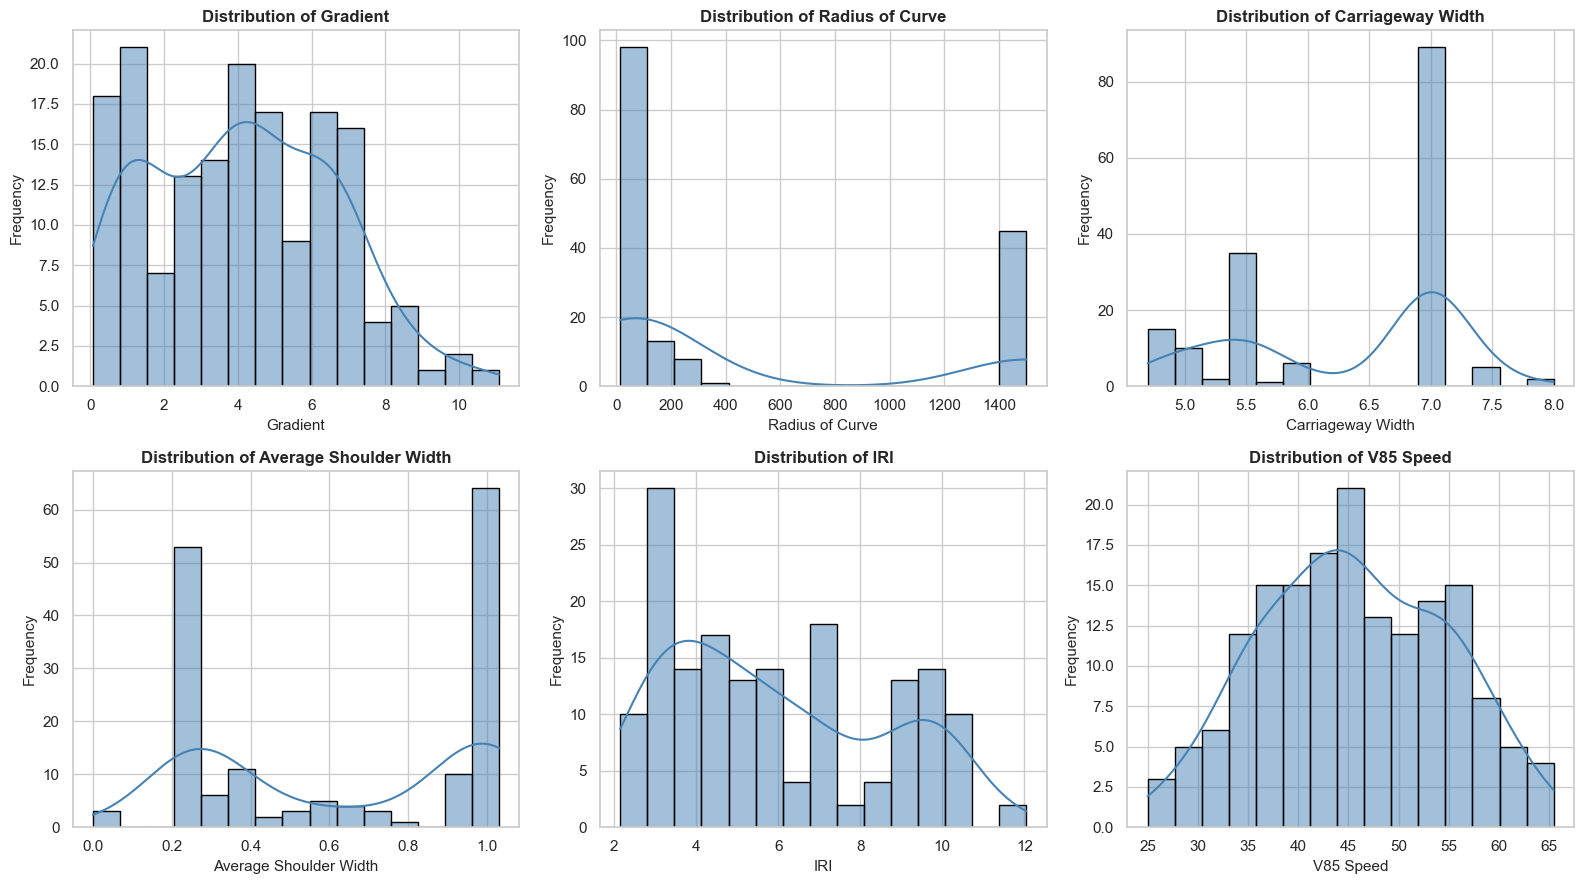

In [10]:
# =============================================
# STEP 7.1: DISTRIBUTION PLOTS
# TWO-WHEELERS
# =============================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Select variables
variables = features + [target]

# Set plot style
sns.set_theme(style="whitegrid")

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

# Plot histograms with KDE
for i, col in enumerate(variables):

    sns.histplot(
        data=df_model,
        x=col,
        kde=True,
        bins=15,
        color="steelblue",
        edgecolor="black",
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {col}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel(col, fontsize=11)
    axes[i].set_ylabel("Frequency", fontsize=11)

# Adjust layout
plt.tight_layout()

plt.show()

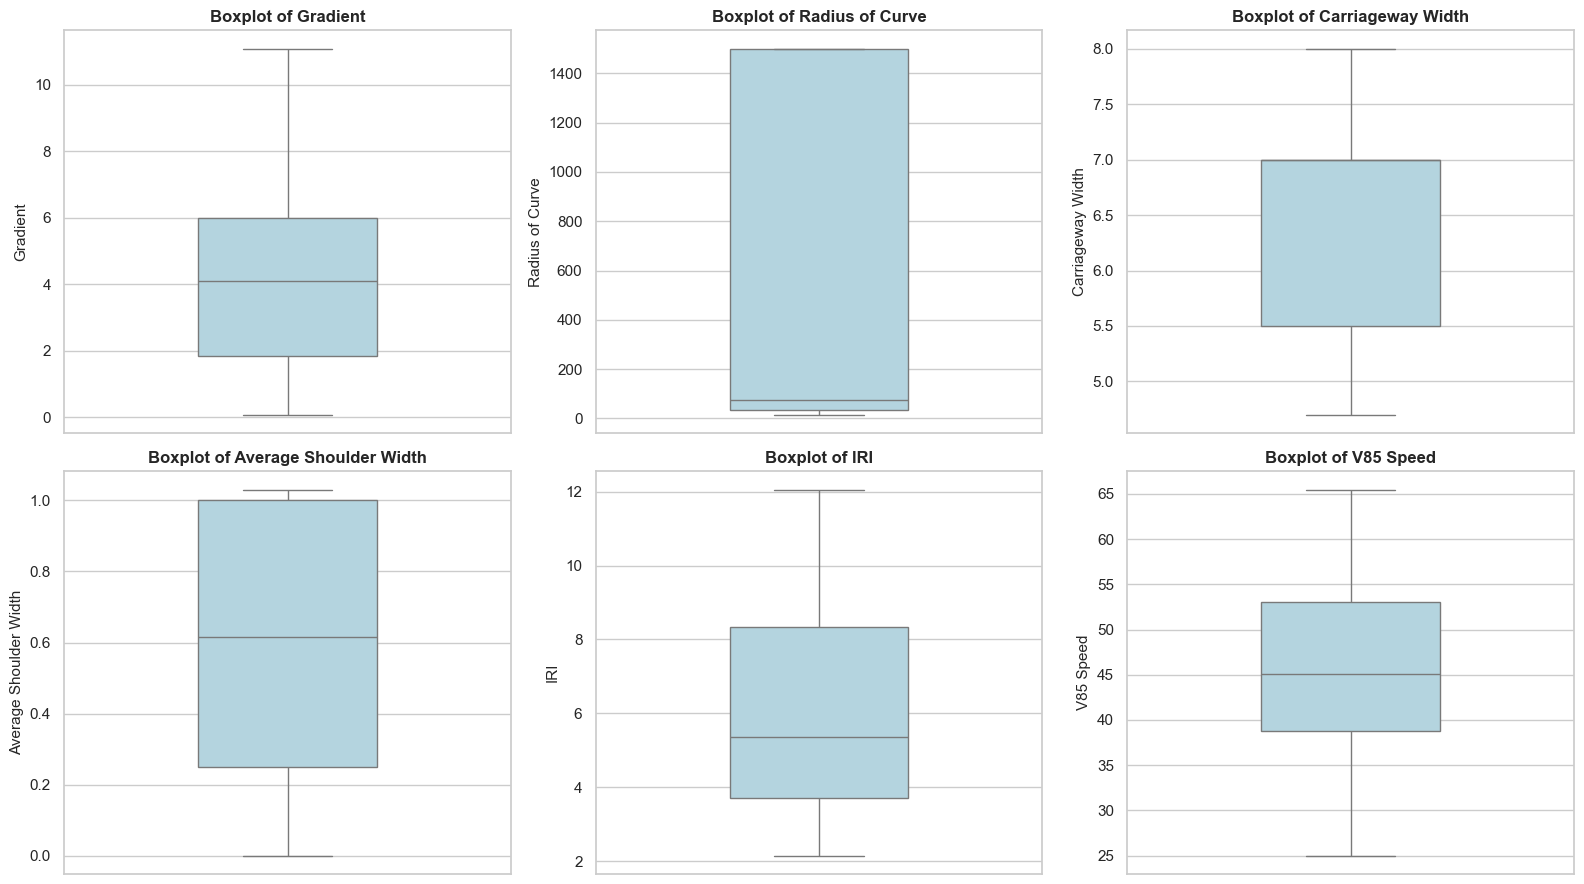

In [11]:
# =============================================
# STEP 7.2: BOXPLOTS
# TWO-WHEELERS
# =============================================

# Select variables
variables = features + [target]

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

# Generate boxplots
for i, col in enumerate(variables):

    sns.boxplot(
        y=df_model[col],
        color="lightblue",
        width=0.4,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Boxplot of {col}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_ylabel(col, fontsize=11)

# Adjust layout
plt.tight_layout()

plt.show()

In [12]:
# =============================================
# STEP 7.3: SKEWNESS ANALYSIS
# TWO-WHEELERS
# =============================================

# Select variables
variables = features + [target]

# Calculate skewness
skewness_data = pd.DataFrame({
    "Variable": variables,
    "Skewness": [
        df_model[col].skew()
        for col in variables
    ]
})

# Classify skewness
def classify_skewness(value):

    if -0.5 <= value <= 0.5:
        return "Approximately Symmetric"

    elif 0.5 < value <= 1:
        return "Moderately Positively Skewed"

    elif -1 <= value < -0.5:
        return "Moderately Negatively Skewed"

    elif value > 1:
        return "Highly Positively Skewed"

    else:
        return "Highly Negatively Skewed"

# Apply classification
skewness_data["Interpretation"] = (
    skewness_data["Skewness"].apply(classify_skewness)
)

# Display results
print("SKEWNESS ANALYSIS - TWO-WHEELERS")
print("=" * 60)

display(skewness_data.round(3))

SKEWNESS ANALYSIS - TWO-WHEELERS


,Variable,Skewness,Interpretation
0,Gradient,0.234,Approximately Symmetric
1,Radius of Curve,0.997,Moderately Positively Skewed
2,Carriageway Width,-0.448,Approximately Symmetric
3,Average Shoulder Width,-0.051,Approximately Symmetric
4,IRI,0.440,Approximately Symmetric
5,V85 Speed,0.016,Approximately Symmetric


CORRELATION MATRIX - TWO-WHEELERS


,Gradient,Radius of Curve,Carriageway Width,Average Shoulder Width,IRI,V85 Speed
Gradient,1.000,-0.180,-0.153,-0.025,-0.133,-0.120
Radius of Curve,-0.180,1.000,0.026,-0.087,0.182,0.548
Carriageway Width,-0.153,0.026,1.000,-0.058,0.307,0.095
Average Shoulder Width,-0.025,-0.087,-0.058,1.000,-0.577,-0.119
IRI,-0.133,0.182,0.307,-0.577,1.000,0.240
V85 Speed,-0.120,0.548,0.095,-0.119,0.240,1.000


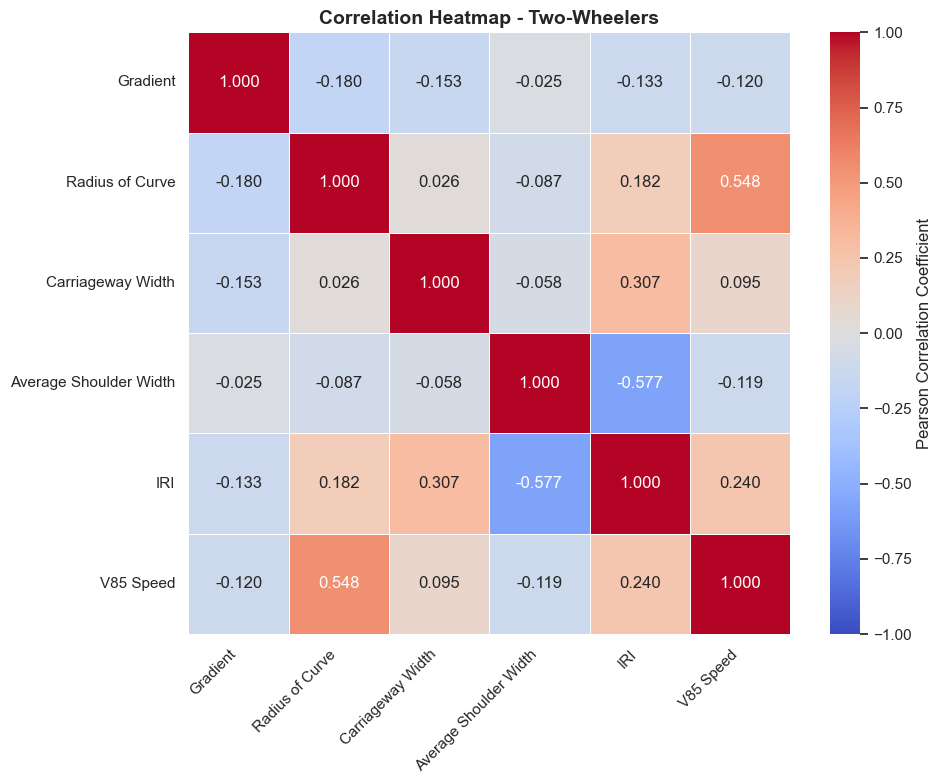

In [13]:
# =============================================
# STEP 7.4: CORRELATION MATRIX AND HEATMAP
# TWO-WHEELERS
# =============================================

# Select variables
variables = features + [target]

# Calculate Pearson correlation matrix
correlation_matrix = df_model[variables].corr(
    method="pearson"
)

# Display correlation matrix
print("CORRELATION MATRIX - TWO-WHEELERS")
print("=" * 60)

display(correlation_matrix.round(3))

# Create heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title(
    "Correlation Heatmap - Two-Wheelers",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

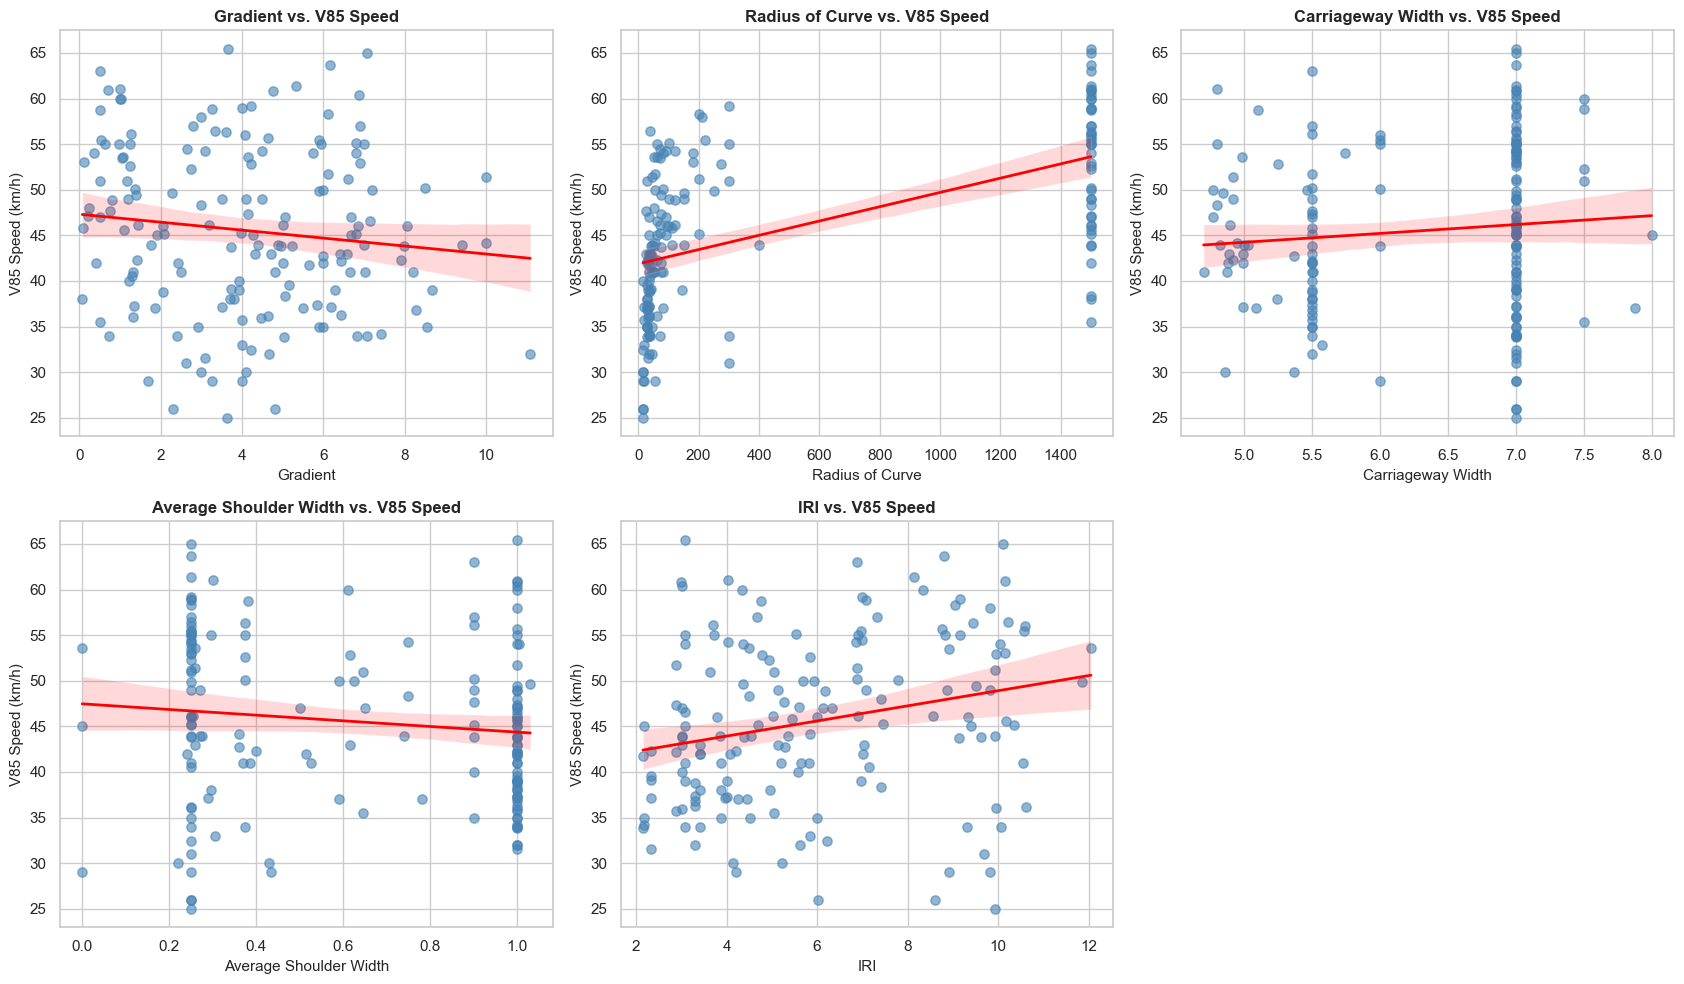

In [14]:
# =============================================
# STEP 7.5: RELATIONSHIP PLOTS
# TWO-WHEELERS
# =============================================

# Define independent variables
features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Define target variable
target = "V85 Speed"

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

# Generate scatterplots with regression lines
for i, col in enumerate(features):

    sns.regplot(
        data=df_model,
        x=col,
        y=target,
        scatter_kws={
            "alpha": 0.6,
            "color": "steelblue",
            "s": 45
        },
        line_kws={
            "color": "red",
            "linewidth": 2
        },
        ci=95,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{col} vs. V85 Speed",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel(col, fontsize=11)
    axes[i].set_ylabel("V85 Speed (km/h)", fontsize=11)

# Remove unused subplot
fig.delaxes(axes[5])

plt.tight_layout()

plt.show()

In [15]:
# =============================================
# STEP 8: TRAIN-TEST SPLITTING
# TWO-WHEELERS
# =============================================

from sklearn.model_selection import train_test_split

# Define independent variables
X = df_model[features]

# Define dependent variable
y = df_model["V85 Speed"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display splitting information
print("TRAIN-TEST SPLITTING - TWO-WHEELERS")
print("=" * 50)

print("Total Observations:", len(X))
print("Training Observations:", len(X_train))
print("Testing Observations:", len(X_test))

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

TRAIN-TEST SPLITTING - TWO-WHEELERS
Total Observations: 165
Training Observations: 132
Testing Observations: 33

Training Features Shape: (132, 5)
Testing Features Shape: (33, 5)

Training Target Shape: (132,)
Testing Target Shape: (33,)


In [16]:
# =============================================
# FIVE-FOLD CROSS-VALIDATION
# TWO-WHEELERS
# =============================================

from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Five-fold cross-validation initialized.")

Five-fold cross-validation initialized.


In [17]:
# =============================================
# STEP 9: MULTIPLE LINEAR REGRESSION (MLR)
# TWO-WHEELERS
# =============================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Initialize MLR model
mlr_model = LinearRegression()

# Train MLR model
mlr_model.fit(X_train, y_train)

# Predict training and testing data
y_train_pred_mlr = mlr_model.predict(X_train)
y_test_pred_mlr = mlr_model.predict(X_test)

# Calculate training performance
train_r2_mlr = r2_score(y_train, y_train_pred_mlr)

train_rmse_mlr = np.sqrt(
    mean_squared_error(y_train, y_train_pred_mlr)
)

train_mae_mlr = mean_absolute_error(
    y_train, y_train_pred_mlr
)

# Calculate testing performance
test_r2_mlr = r2_score(y_test, y_test_pred_mlr)

test_rmse_mlr = np.sqrt(
    mean_squared_error(y_test, y_test_pred_mlr)
)

test_mae_mlr = mean_absolute_error(
    y_test, y_test_pred_mlr
)

# Create performance comparison table
mlr_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R²": [train_r2_mlr, test_r2_mlr],
    "RMSE (km/h)": [train_rmse_mlr, test_rmse_mlr],
    "MAE (km/h)": [train_mae_mlr, test_mae_mlr]
})

print("MLR MODEL PERFORMANCE - TWO-WHEELERS")
print("=" * 60)

display(mlr_results.round(4))

MLR MODEL PERFORMANCE - TWO-WHEELERS


,Dataset,R²,RMSE (km/h),MAE (km/h)
0,Training,0.3481,7.5245,6.0034
1,Testing,0.1373,7.3470,6.1127


In [18]:
# =============================================
# STEP 9.2: MLR REGRESSION COEFFICIENTS
# TWO-WHEELERS
# =============================================

# Create coefficient table
mlr_coefficients = pd.DataFrame({
    "Variable": X_train.columns,
    "Coefficient": mlr_model.coef_
})

# Display intercept
print("MLR REGRESSION COEFFICIENTS - TWO-WHEELERS")
print("=" * 60)

print("\nIntercept:", round(mlr_model.intercept_, 4))

print("\nRegression Coefficients:")
display(mlr_coefficients.round(4))

MLR REGRESSION COEFFICIENTS - TWO-WHEELERS

Intercept: 35.9374

Regression Coefficients:


,Variable,Coefficient
0,Gradient,0.0008
1,Radius of Curve,0.0079
2,Carriageway Width,0.6529
3,Average Shoulder Width,-0.1875
4,IRI,0.3197


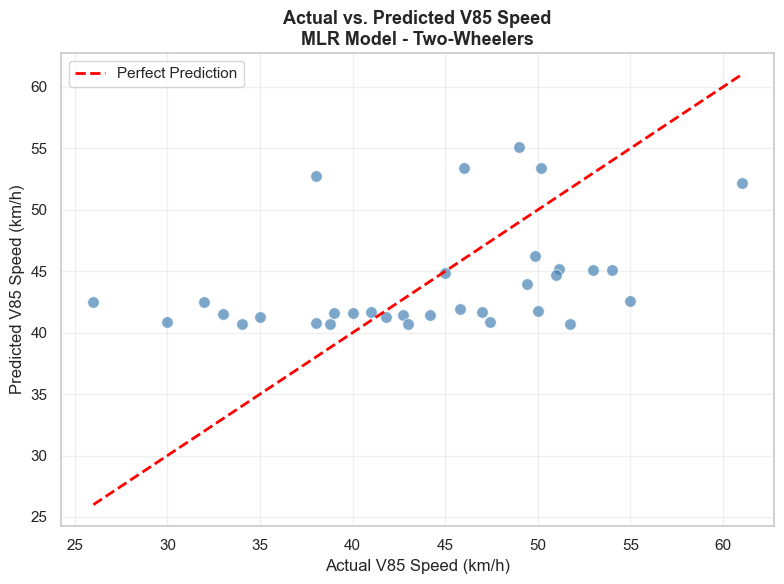

In [19]:
# =============================================
# STEP 9.3: ACTUAL VS PREDICTED SPEED
# TWO-WHEELERS - MLR
# =============================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

# Scatterplot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_mlr,
    color="steelblue",
    s=70,
    alpha=0.7
)

# Perfect prediction line
min_val = min(y_test.min(), y_test_pred_mlr.min())
max_val = max(y_test.max(), y_test_pred_mlr.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Actual vs. Predicted V85 Speed\n"
    "MLR Model - Two-Wheelers",
    fontsize=13,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [20]:
# =============================================
# STEP 10.1: RANDOM FOREST HYPERPARAMETER GRID
# TWO-WHEELERS
# =============================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import numpy as np
import pandas as pd

# Define RF hyperparameter grid
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

print("RANDOM FOREST HYPERPARAMETER GRID - TWO-WHEELERS")
print("=" * 60)

print(param_grid_rf)

RANDOM FOREST HYPERPARAMETER GRID - TWO-WHEELERS
{'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10, 15], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 'log2']}


In [21]:
# =============================================
# STEP 10.2: TUNED RANDOM FOREST MODEL
# TWO-WHEELERS
# =============================================

# Initialize Random Forest
rf_model = RandomForestRegressor(
    random_state=42
)

# Define GridSearchCV
grid_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train tuned Random Forest
grid_rf.fit(X_train, y_train)

# Extract best model
best_rf = grid_rf.best_estimator_

# Display best hyperparameters
print("TUNED RANDOM FOREST - TWO-WHEELERS")
print("=" * 60)

print("\nBest Hyperparameters:")
print(grid_rf.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-grid_rf.best_score_, 4), "km/h")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
TUNED RANDOM FOREST - TWO-WHEELERS

Best Hyperparameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}

Best Cross-Validation RMSE:
7.077 km/h


In [22]:
# =============================================
# STEP 10.3: RANDOM FOREST MODEL EVALUATION
# TWO-WHEELERS
# =============================================

# Predict training and testing data
y_train_pred_rf = best_rf.predict(X_train)
y_test_pred_rf = best_rf.predict(X_test)

# Training performance
train_r2_rf = r2_score(
    y_train, y_train_pred_rf
)

train_rmse_rf = np.sqrt(
    mean_squared_error(y_train, y_train_pred_rf)
)

train_mae_rf = mean_absolute_error(
    y_train, y_train_pred_rf
)

# Testing performance
test_r2_rf = r2_score(
    y_test, y_test_pred_rf
)

test_rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_test_pred_rf)
)

test_mae_rf = mean_absolute_error(
    y_test, y_test_pred_rf
)

# Create performance comparison table
rf_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R²": [train_r2_rf, test_r2_rf],
    "RMSE (km/h)": [train_rmse_rf, test_rmse_rf],
    "MAE (km/h)": [train_mae_rf, test_mae_rf]
})

print("TUNED RANDOM FOREST PERFORMANCE - TWO-WHEELERS")
print("=" * 60)

display(rf_results.round(4))

TUNED RANDOM FOREST PERFORMANCE - TWO-WHEELERS


,Dataset,R²,RMSE (km/h),MAE (km/h)
0,Training,0.8102,4.0596,3.1192
1,Testing,0.4793,5.7079,4.6299


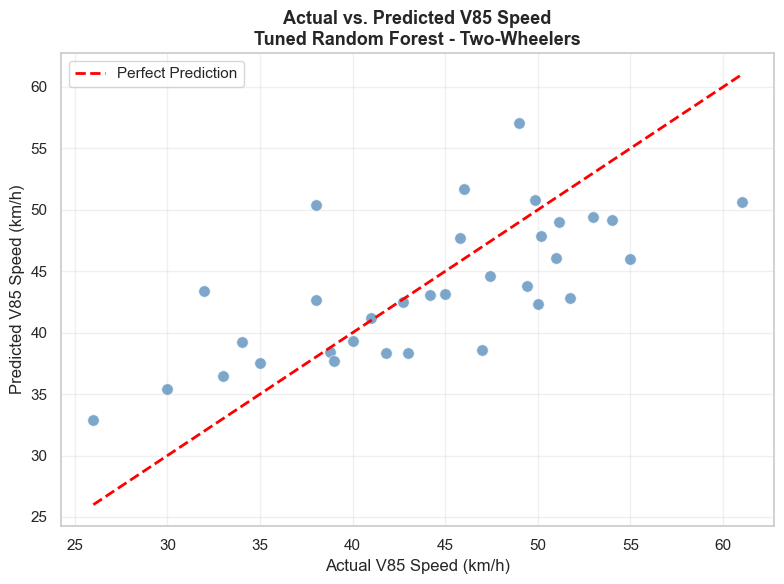

In [23]:
# =============================================
# STEP 10.4: ACTUAL VS PREDICTED SPEED
# TUNED RANDOM FOREST - TWO-WHEELERS
# =============================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

# Scatterplot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_rf,
    color="steelblue",
    s=70,
    alpha=0.7
)

# Perfect prediction line
min_val = min(y_test.min(), y_test_pred_rf.min())
max_val = max(y_test.max(), y_test_pred_rf.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Actual vs. Predicted V85 Speed\n"
    "Tuned Random Forest - Two-Wheelers",
    fontsize=13,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [24]:
# =============================================
# STEP 10.5: RANDOM FOREST FEATURE IMPORTANCE
# TWO-WHEELERS
# =============================================

# Extract feature importance
rf_importance = best_rf.feature_importances_

# Create feature importance table
rf_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_importance
})

# Sort by importance
rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST FEATURE IMPORTANCE - TWO-WHEELERS")
print("=" * 60)

display(rf_feature_importance.round(4))

RANDOM FOREST FEATURE IMPORTANCE - TWO-WHEELERS


,Feature,Importance
0,Radius of Curve,0.5228
1,IRI,0.1835
2,Gradient,0.1765
3,Average Shoulder Width,0.0625
4,Carriageway Width,0.0547


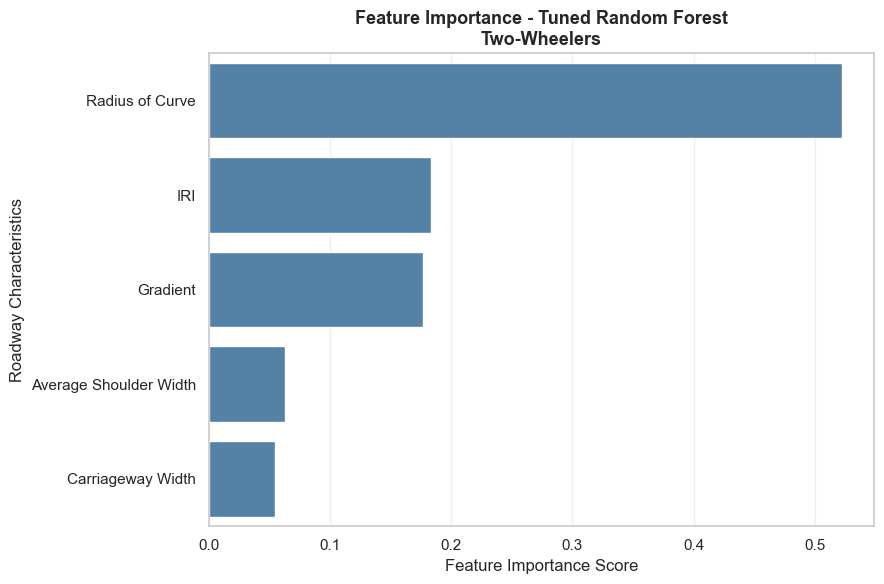

In [25]:
# =============================================
# STEP 10.6: RANDOM FOREST FEATURE IMPORTANCE PLOT
# TWO-WHEELERS
# =============================================

plt.figure(figsize=(9, 6))

sns.barplot(
    data=rf_feature_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Feature Importance - Tuned Random Forest\n"
    "Two-Wheelers",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Roadway Characteristics")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.show()

In [26]:
# =============================================
# STEP 10.7: MLR VS TUNED RANDOM FOREST
# TWO-WHEELERS
# =============================================

# Create model comparison table
comparison_mlr_rf = pd.DataFrame({
    "Model": [
        "MLR",
        "Tuned Random Forest"
    ],
    "R²": [
        test_r2_mlr,
        test_r2_rf
    ],
    "RMSE (km/h)": [
        test_rmse_mlr,
        test_rmse_rf
    ],
    "MAE (km/h)": [
        test_mae_mlr,
        test_mae_rf
    ]
})

print("MODEL PERFORMANCE COMPARISON - TWO-WHEELERS")
print("=" * 60)

display(comparison_mlr_rf.round(4))

MODEL PERFORMANCE COMPARISON - TWO-WHEELERS


,Model,R²,RMSE (km/h),MAE (km/h)
0,MLR,0.1373,7.3470,6.1127
1,Tuned Random Forest,0.4793,5.7079,4.6299


In [27]:
# =============================================
# STEP 11.1: XGBOOST HYPERPARAMETER GRID
# TWO-WHEELERS
# =============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Define XGBoost hyperparameter grid
param_grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

print("XGBOOST HYPERPARAMETER GRID - TWO-WHEELERS")
print("=" * 60)

print(param_grid_xgb)

XGBOOST HYPERPARAMETER GRID - TWO-WHEELERS
{'n_estimators': [100, 200], 'max_depth': [3, 4, 5], 'learning_rate': [0.01, 0.05, 0.1], 'subsample': [0.7, 0.8, 1.0], 'colsample_bytree': [0.7, 0.8, 1.0]}


In [28]:
# =============================================
# STEP 11.2: TUNED XGBOOST MODEL
# TWO-WHEELERS
# =============================================

# Initialize XGBoost model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1,
    importance_type="gain"
)

# Define GridSearchCV
grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid_xgb,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train tuned XGBoost
grid_xgb.fit(X_train, y_train)

# Extract best model
best_xgb = grid_xgb.best_estimator_

# Display best hyperparameters
print("TUNED XGBOOST - TWO-WHEELERS")
print("=" * 60)

print("\nBest Hyperparameters:")
print(grid_xgb.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-grid_xgb.best_score_, 4), "km/h")

Fitting 5 folds for each of 162 candidates, totalling 810 fits
TUNED XGBOOST - TWO-WHEELERS

Best Hyperparameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.7}

Best Cross-Validation RMSE:
7.2599 km/h


In [29]:
# =============================================
# STEP 11.3: XGBOOST MODEL EVALUATION
# TWO-WHEELERS
# =============================================

# Predict training and testing data
y_train_pred_xgb = best_xgb.predict(X_train)
y_test_pred_xgb = best_xgb.predict(X_test)

# Training performance
train_r2_xgb = r2_score(
    y_train, y_train_pred_xgb
)

train_rmse_xgb = np.sqrt(
    mean_squared_error(y_train, y_train_pred_xgb)
)

train_mae_xgb = mean_absolute_error(
    y_train, y_train_pred_xgb
)

# Testing performance
test_r2_xgb = r2_score(
    y_test, y_test_pred_xgb
)

test_rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_test_pred_xgb)
)

test_mae_xgb = mean_absolute_error(
    y_test, y_test_pred_xgb
)

# Create performance comparison table
xgb_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R²": [train_r2_xgb, test_r2_xgb],
    "RMSE (km/h)": [train_rmse_xgb, test_rmse_xgb],
    "MAE (km/h)": [train_mae_xgb, test_mae_xgb]
})

print("TUNED XGBOOST PERFORMANCE - TWO-WHEELERS")
print("=" * 60)

display(xgb_results.round(4))

TUNED XGBOOST PERFORMANCE - TWO-WHEELERS


,Dataset,R²,RMSE (km/h),MAE (km/h)
0,Training,0.6697,5.3563,4.2260
1,Testing,0.4603,5.8110,4.5897


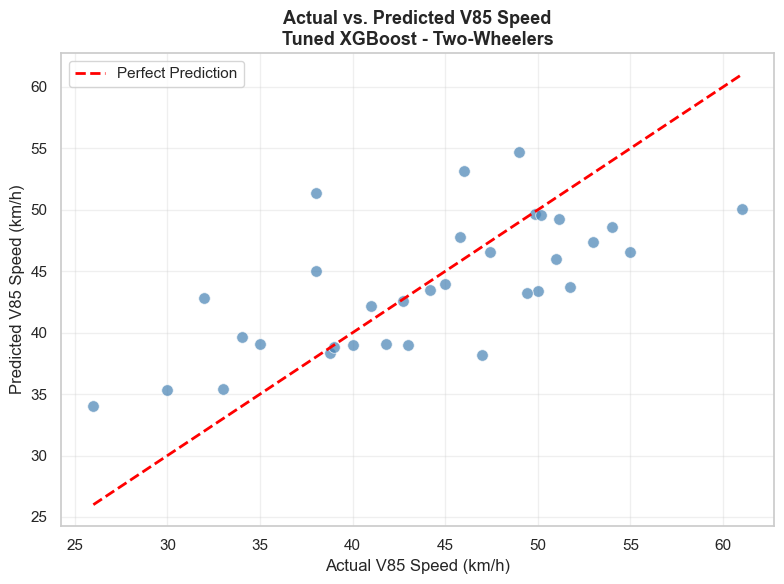

In [30]:
# =============================================
# STEP 11.4: ACTUAL VS PREDICTED SPEED
# TUNED XGBOOST - TWO-WHEELERS
# =============================================

plt.figure(figsize=(8, 6))

# Scatterplot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_xgb,
    color="steelblue",
    s=70,
    alpha=0.7
)

# Perfect prediction line
min_val = min(y_test.min(), y_test_pred_xgb.min())
max_val = max(y_test.max(), y_test_pred_xgb.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Actual vs. Predicted V85 Speed\n"
    "Tuned XGBoost - Two-Wheelers",
    fontsize=13,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [31]:
# =============================================
# STEP 11.5: XGBOOST FEATURE IMPORTANCE
# TWO-WHEELERS
# =============================================

# Extract feature importance
xgb_importance = best_xgb.feature_importances_

# Create feature importance table
xgb_feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_importance
})

# Sort by importance
xgb_feature_importance = xgb_feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("XGBOOST FEATURE IMPORTANCE - TWO-WHEELERS")
print("=" * 60)

display(xgb_feature_importance.round(4))

XGBOOST FEATURE IMPORTANCE - TWO-WHEELERS


,Feature,Importance
0,Radius of Curve,0.5431
1,Carriageway Width,0.1287
2,IRI,0.1183
3,Gradient,0.1117
4,Average Shoulder Width,0.0982


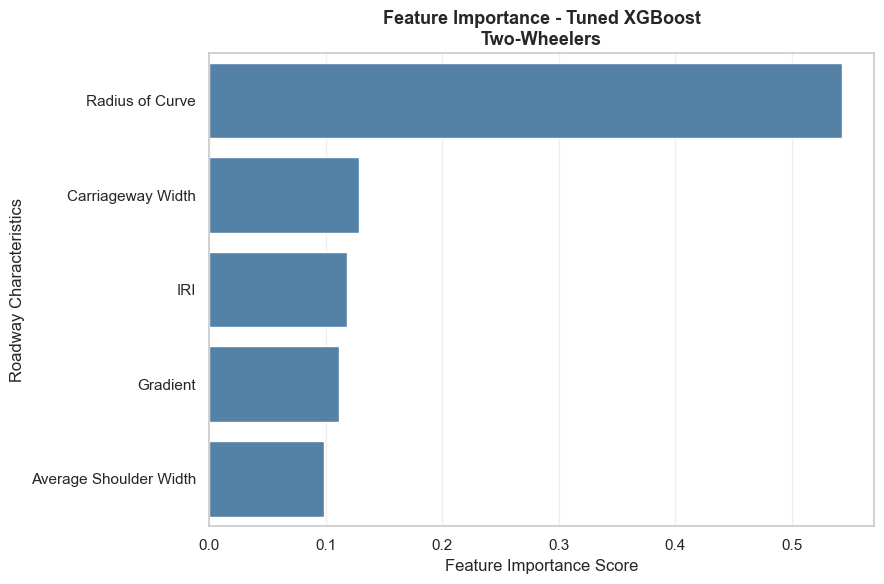

In [32]:
# =============================================
# STEP 11.6: XGBOOST FEATURE IMPORTANCE PLOT
# TWO-WHEELERS
# =============================================

plt.figure(figsize=(9, 6))

sns.barplot(
    data=xgb_feature_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Feature Importance - Tuned XGBoost\n"
    "Two-Wheelers",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Roadway Characteristics")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.show()

In [33]:
# =============================================
# STEP 11.7: MODEL PERFORMANCE COMPARISON
# TWO-WHEELERS
# =============================================

# Create comparison table
comparison_models = pd.DataFrame({
    "Model": [
        "MLR",
        "Tuned Random Forest",
        "Tuned XGBoost"
    ],

    "R²": [
        test_r2_mlr,
        test_r2_rf,
        test_r2_xgb
    ],

    "RMSE (km/h)": [
        test_rmse_mlr,
        test_rmse_rf,
        test_rmse_xgb
    ],

    "MAE (km/h)": [
        test_mae_mlr,
        test_mae_rf,
        test_mae_xgb
    ]
})

# Sort by RMSE
comparison_models = comparison_models.sort_values(
    by="RMSE (km/h)",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON - TWO-WHEELERS")
print("=" * 60)

display(comparison_models.round(4))

MODEL PERFORMANCE COMPARISON - TWO-WHEELERS


,Model,R²,RMSE (km/h),MAE (km/h)
0,Tuned Random Forest,0.4793,5.7079,4.6299
1,Tuned XGBoost,0.4603,5.8110,4.5897
2,MLR,0.1373,7.3470,6.1127


In [34]:
# =============================================
# STEP 12.1: SVR HYPERPARAMETER GRID
# TWO-WHEELERS
# =============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Define SVR pipeline
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

# Define SVR hyperparameter grid
param_grid_svr = {
    "svr__C": [1, 10, 100, 1000],
    "svr__epsilon": [0.01, 0.1, 0.5, 1],
    "svr__gamma": ["scale", 0.001, 0.01, 0.1, 1],
    "svr__kernel": ["rbf"]
}

print("SVR HYPERPARAMETER GRID - TWO-WHEELERS")
print("=" * 60)

print(param_grid_svr)

SVR HYPERPARAMETER GRID - TWO-WHEELERS
{'svr__C': [1, 10, 100, 1000], 'svr__epsilon': [0.01, 0.1, 0.5, 1], 'svr__gamma': ['scale', 0.001, 0.01, 0.1, 1], 'svr__kernel': ['rbf']}


In [35]:
# =============================================
# STEP 12.2: TUNED SVR MODEL
# TWO-WHEELERS
# =============================================

# Define GridSearchCV
grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid_svr,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train tuned SVR model
grid_svr.fit(X_train, y_train)

# Extract best model
best_svr = grid_svr.best_estimator_

# Display best hyperparameters
print("TUNED SVR - TWO-WHEELERS")
print("=" * 60)

print("\nBest Hyperparameters:")
print(grid_svr.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-grid_svr.best_score_, 4), "km/h")

Fitting 5 folds for each of 80 candidates, totalling 400 fits
TUNED SVR - TWO-WHEELERS

Best Hyperparameters:
{'svr__C': 1000, 'svr__epsilon': 1, 'svr__gamma': 0.001, 'svr__kernel': 'rbf'}

Best Cross-Validation RMSE:
7.9453 km/h


In [36]:
# =============================================
# STEP 12.3: SVR MODEL EVALUATION
# TWO-WHEELERS
# =============================================

# Predict training and testing data
y_train_pred_svr = best_svr.predict(X_train)
y_test_pred_svr = best_svr.predict(X_test)

# Training performance
train_r2_svr = r2_score(
    y_train, y_train_pred_svr
)

train_rmse_svr = np.sqrt(
    mean_squared_error(y_train, y_train_pred_svr)
)

train_mae_svr = mean_absolute_error(
    y_train, y_train_pred_svr
)

# Testing performance
test_r2_svr = r2_score(
    y_test, y_test_pred_svr
)

test_rmse_svr = np.sqrt(
    mean_squared_error(y_test, y_test_pred_svr)
)

test_mae_svr = mean_absolute_error(
    y_test, y_test_pred_svr
)

# Create performance comparison table
svr_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R²": [train_r2_svr, test_r2_svr],
    "RMSE (km/h)": [train_rmse_svr, test_rmse_svr],
    "MAE (km/h)": [train_mae_svr, test_mae_svr]
})

print("TUNED SVR PERFORMANCE - TWO-WHEELERS")
print("=" * 60)

display(svr_results.round(4))

TUNED SVR PERFORMANCE - TWO-WHEELERS


,Dataset,R²,RMSE (km/h),MAE (km/h)
0,Training,0.3507,7.5096,5.9318
1,Testing,0.1269,7.3912,6.1051


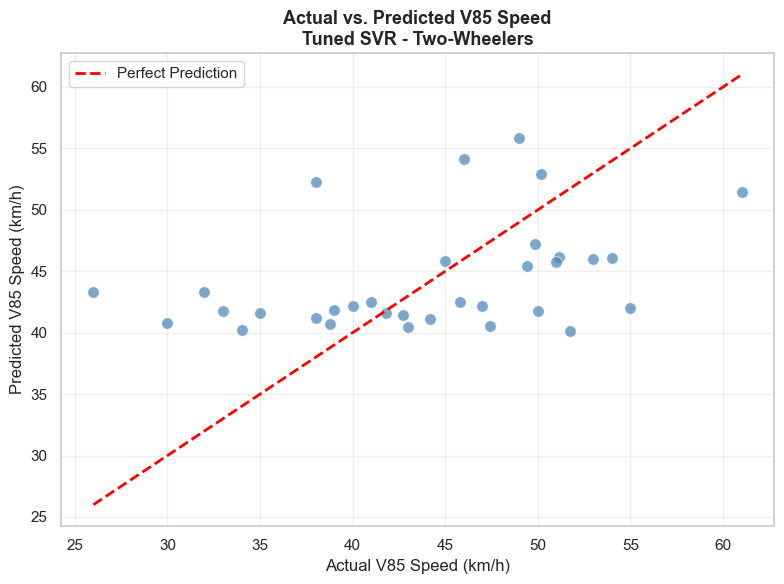

In [37]:
# =============================================
# STEP 12.4: ACTUAL VS PREDICTED SPEED
# TUNED SVR - TWO-WHEELERS
# =============================================

plt.figure(figsize=(8, 6))

# Scatterplot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_svr,
    color="steelblue",
    s=70,
    alpha=0.7
)

# Perfect prediction line
min_val = min(y_test.min(), y_test_pred_svr.min())
max_val = max(y_test.max(), y_test_pred_svr.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Actual vs. Predicted V85 Speed\n"
    "Tuned SVR - Two-Wheelers",
    fontsize=13,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [38]:
# =============================================
# STEP 12.5: MODEL PERFORMANCE COMPARISON
# TWO-WHEELERS
# =============================================

# Create model comparison table
comparison_models = pd.DataFrame({
    "Model": [
        "MLR",
        "Tuned Random Forest",
        "Tuned XGBoost",
        "Tuned SVR"
    ],

    "R²": [
        test_r2_mlr,
        test_r2_rf,
        test_r2_xgb,
        test_r2_svr
    ],

    "RMSE (km/h)": [
        test_rmse_mlr,
        test_rmse_rf,
        test_rmse_xgb,
        test_rmse_svr
    ],

    "MAE (km/h)": [
        test_mae_mlr,
        test_mae_rf,
        test_mae_xgb,
        test_mae_svr
    ]
})

# Sort models by testing RMSE
comparison_models = comparison_models.sort_values(
    by="RMSE (km/h)",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON - TWO-WHEELERS")
print("=" * 60)

display(comparison_models.round(4))

MODEL PERFORMANCE COMPARISON - TWO-WHEELERS


,Model,R²,RMSE (km/h),MAE (km/h)
0,Tuned Random Forest,0.4793,5.7079,4.6299
1,Tuned XGBoost,0.4603,5.8110,4.5897
2,MLR,0.1373,7.3470,6.1127
3,Tuned SVR,0.1269,7.3912,6.1051


In [39]:
# =============================================
# STEP 13.1: ANN HYPERPARAMETER GRID
# TWO-WHEELERS
# =============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Define ANN pipeline
ann_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPRegressor(
        max_iter=3000,
        random_state=42
    ))
])

# Define ANN hyperparameter grid
param_grid_ann = {
    "ann__hidden_layer_sizes": [
        (32,),
        (64,),
        (64, 32),
        (128, 64)
    ],
    "ann__activation": ["relu", "tanh"],
    "ann__alpha": [0.0001, 0.001, 0.01],
    "ann__learning_rate_init": [0.001, 0.01]
}

print("ANN HYPERPARAMETER GRID - TWO-WHEELERS")
print("=" * 60)

print(param_grid_ann)

ANN HYPERPARAMETER GRID - TWO-WHEELERS
{'ann__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64)], 'ann__activation': ['relu', 'tanh'], 'ann__alpha': [0.0001, 0.001, 0.01], 'ann__learning_rate_init': [0.001, 0.01]}


In [40]:
# =============================================
# STEP 13.2: TUNED ANN MODEL
# TWO-WHEELERS
# =============================================

# Define GridSearchCV
grid_ann = GridSearchCV(
    estimator=ann_pipeline,
    param_grid=param_grid_ann,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train tuned ANN model
grid_ann.fit(X_train, y_train)

# Extract best model
best_ann = grid_ann.best_estimator_

# Display best hyperparameters
print("TUNED ANN - TWO-WHEELERS")
print("=" * 60)

print("\nBest Hyperparameters:")
print(grid_ann.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-grid_ann.best_score_, 4), "km/h")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
TUNED ANN - TWO-WHEELERS

Best Hyperparameters:
{'ann__activation': 'tanh', 'ann__alpha': 0.0001, 'ann__hidden_layer_sizes': (64,), 'ann__learning_rate_init': 0.001}

Best Cross-Validation RMSE:
7.8266 km/h


In [41]:
# =============================================
# STEP 13.3: ANN MODEL EVALUATION
# TWO-WHEELERS
# =============================================

# Predict training and testing data
y_train_pred_ann = best_ann.predict(X_train)
y_test_pred_ann = best_ann.predict(X_test)

# Training performance
train_r2_ann = r2_score(
    y_train, y_train_pred_ann
)

train_rmse_ann = np.sqrt(
    mean_squared_error(y_train, y_train_pred_ann)
)

train_mae_ann = mean_absolute_error(
    y_train, y_train_pred_ann
)

# Testing performance
test_r2_ann = r2_score(
    y_test, y_test_pred_ann
)

test_rmse_ann = np.sqrt(
    mean_squared_error(y_test, y_test_pred_ann)
)

test_mae_ann = mean_absolute_error(
    y_test, y_test_pred_ann
)

# Create performance comparison table
ann_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R²": [train_r2_ann, test_r2_ann],
    "RMSE (km/h)": [train_rmse_ann, test_rmse_ann],
    "MAE (km/h)": [train_mae_ann, test_mae_ann]
})

print("TUNED ANN PERFORMANCE - TWO-WHEELERS")
print("=" * 60)

display(ann_results.round(4))

TUNED ANN PERFORMANCE - TWO-WHEELERS


,Dataset,R²,RMSE (km/h),MAE (km/h)
0,Training,0.5441,6.2922,4.9553
1,Testing,-0.0608,8.1468,6.5938


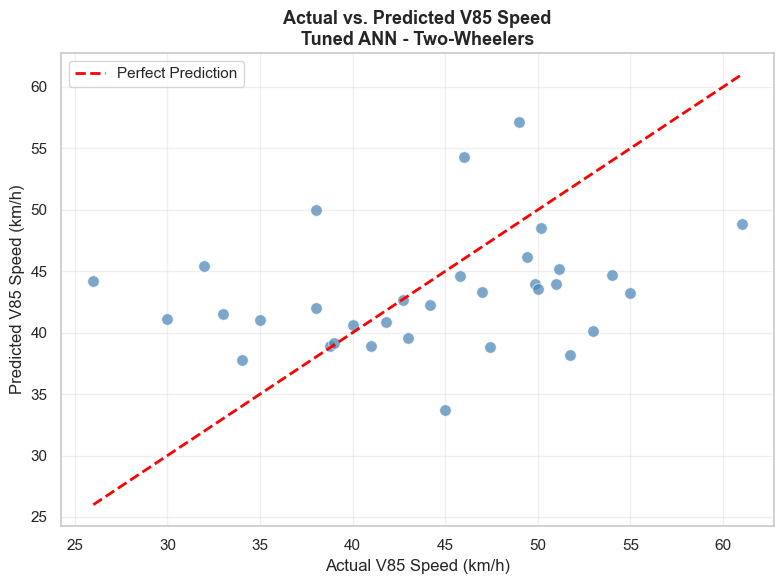

In [42]:
# =============================================
# STEP 13.4: ACTUAL VS PREDICTED SPEED
# TUNED ANN - TWO-WHEELERS
# =============================================

plt.figure(figsize=(8, 6))

# Scatterplot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_ann,
    color="steelblue",
    s=70,
    alpha=0.7
)

# Perfect prediction line
min_val = min(y_test.min(), y_test_pred_ann.min())
max_val = max(y_test.max(), y_test_pred_ann.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Actual vs. Predicted V85 Speed\n"
    "Tuned ANN - Two-Wheelers",
    fontsize=13,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [43]:
# =============================================
# STEP 13.5: FINAL MODEL PERFORMANCE COMPARISON
# TWO-WHEELERS
# =============================================

# Create final model comparison table
final_comparison = pd.DataFrame({
    "Model": [
        "MLR",
        "Tuned Random Forest",
        "Tuned XGBoost",
        "Tuned SVR",
        "Tuned ANN"
    ],

    "R²": [
        test_r2_mlr,
        test_r2_rf,
        test_r2_xgb,
        test_r2_svr,
        test_r2_ann
    ],

    "RMSE (km/h)": [
        test_rmse_mlr,
        test_rmse_rf,
        test_rmse_xgb,
        test_rmse_svr,
        test_rmse_ann
    ],

    "MAE (km/h)": [
        test_mae_mlr,
        test_mae_rf,
        test_mae_xgb,
        test_mae_svr,
        test_mae_ann
    ]
})

# Sort models by testing RMSE
final_comparison = final_comparison.sort_values(
    by="RMSE (km/h)",
    ascending=True
).reset_index(drop=True)

# Display comparison table
print("FINAL MODEL PERFORMANCE COMPARISON - TWO-WHEELERS")
print("=" * 70)

display(final_comparison.round(4))

FINAL MODEL PERFORMANCE COMPARISON - TWO-WHEELERS


,Model,R²,RMSE (km/h),MAE (km/h)
0,Tuned Random Forest,0.4793,5.7079,4.6299
1,Tuned XGBoost,0.4603,5.8110,4.5897
2,MLR,0.1373,7.3470,6.1127
3,Tuned SVR,0.1269,7.3912,6.1051
4,Tuned ANN,-0.0608,8.1468,6.5938


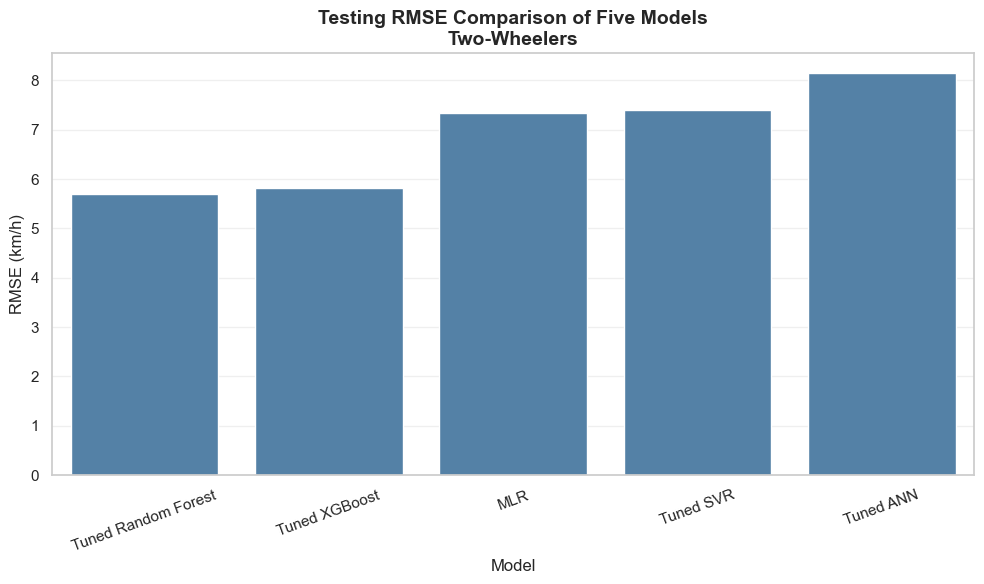

In [44]:
# =============================================
# STEP 13.6: MODEL COMPARISON PLOT
# TWO-WHEELERS
# =============================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_comparison,
    x="Model",
    y="RMSE (km/h)",
    color="steelblue"
)

plt.title(
    "Testing RMSE Comparison of Five Models\n"
    "Two-Wheelers",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("RMSE (km/h)")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()